https://www.kaggle.com/code/onurkoc83/quantum-machine-learning-tutorial

In [3]:
import pandas as pd
from sklearn import model_selection, datasets, svm
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import QiskitRuntimeService
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('Heart_data.csv')

X = df[['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']].values
Y = df['HeartDisease'].values

X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42
)

X_train = (X_train - X_train.min(0)) / (X_train.max(0) - X_train.min(0) + 1e-12)
X_test  = (X_test  - X_train.min(0)) / (X_train.max(0) - X_train.min(0) + 1e-12)

N = X.shape[1]
q = QuantumRegister(N)
c = ClassicalRegister(1)
qc = QuantumCircuit(q, c)

for i, x in enumerate(X_train[0]):
    qc.rx(x, i)

def feature_map(X):
    q = QuantumRegister(N)
    qc = QuantumCircuit(q)          # ← NO classical register here!
    for i, x in enumerate(X):
        qc.rx(x * np.pi, i)         # ← also multiply by π — helps a lot
    return qc

qc, c = feature_map(X_train[5])

qc.measure_all()

qc, c = feature_map(X_train[5])

qc.barrier()

qc.barrier()

qc.measure_all()

def variational_circuit(qc, theta):
    N = qc.num_qubits  # Get the number of qubits directly from the circuit

    # Apply CNOT gates between adjacent qubits (Linear Entangler)
    for i in range(N - 1):
        # Correct: use qc.cx() instead of qc.cnot()
        qc.cx(i, i + 1)

    # Apply CNOT gate from the last to the first qubit (Periodic Entangler)
    # Correct: use qc.cx() instead of qc.cnot()
    qc.cx(N - 1, 0)
    
    # Apply RY rotation to every qubit
    for i in range(N):
        qc.ry(theta[i], i)
        
    return qc

import numpy as np
qc, c =feature_map(X_train[5])

qc.barrier()

qc = variational_circuit(qc, np.random.rand(N))

qc.barrier()

qc.measure_all()

def quantum_nn(X, theta, simulator=True):
    qc = feature_map(X)                 # ← now returns only qc
    qc = variational_circuit(qc, theta)
    qc.measure_all()                    # ← this now adds 6 clean classical bits

    shots = 10000
    backend = AerSimulator()
    result = backend.run(qc, shots=shots).result()
    counts = result.get_counts()

    prob_class_1 = sum(v for k, v in counts.items() if k.count('1') % 2 == 1) / shots
    return prob_class_1

prediction = quantum_nn(X_train[5], np.random.rand(N))
prediction

target = Y_train[5]
target

(target - prediction)**2

def loss(prediction, target):
      return (target - prediction)**2

loss(prediction, target)

import copy

def gradient(X, Y, theta):
    
      delta = 0.01

      grad = []
    
      for i in range(len(theta)):

          dtheta = copy.copy(theta)  # shallow copy
          dtheta[i] += delta

          pred1 = quantum_nn(X, dtheta)
          pred2 = quantum_nn(X, theta)
          # finite difference
          grad.append( (loss(pred1, Y)-loss(pred2, Y))/ delta)

      return np.array(grad)

def accuracy(X, Y, theta):

      counter = 0
      for X_i, Y_i in zip(X, Y):

          prediction = quantum_nn(X_i, theta)

          if prediction < 0.5 and Y_i == 0:
               counter +=1
          elif prediction >= 0.5 and Y_i == 1:
               counter +=1
      return counter/len(Y)

eta = 0.05
theta = np.random.uniform(-np.pi, np.pi, N)
loss_list = []

print("Epoch \t Loss \t Training Accuracy")
for i in range(50):
    loss_tmp = []
    for X_i, Y_i in zip(X_train, Y_train):
        prediction = quantum_nn(X_i, theta)        # now X_i is in [0,1] → perfect
        loss_tmp.append(loss(prediction, Y_i))
        theta = theta - eta * gradient(X_i, Y_i, theta)
   
    loss_list.append(np.mean(loss_tmp))
    acc = accuracy(X_train, Y_train, theta)
    print(f"{i+1:2d} \t {loss_list[-1]:.4f} \t {acc:.4f}")

accuracy(X_test, Y_test, theta)

ValueError: too many values to unpack (expected 2)

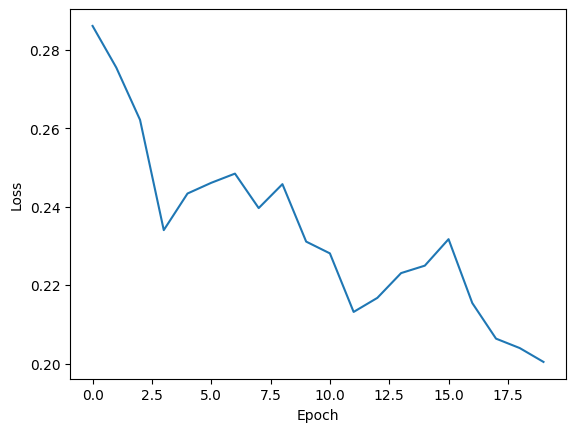

In [30]:
import matplotlib.pyplot as plt

plt.plot(loss_list)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

In [31]:
accuracy(X_test, Y_test, theta)

0.7575757575757576

In [32]:
clf = svm.SVC()
clf.fit(X_train, Y_train)

print(clf.predict(X_test))
print(Y_test)

[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1]
[1 1 1 0 0 0 0 1 0 0 0 0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 1]


Train: 335, Test: 165
Computing kernel 335×335 (shots=2048) ... 

/tmp/ipykernel_844828/3709822244.py:31: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=N, reps=2, entanglement='linear')


done
Computing kernel 165×335 (shots=2048) ... done

QUANTUM SVM ACCURACY: 65.45%
Classical RBF SVM: 87.88%


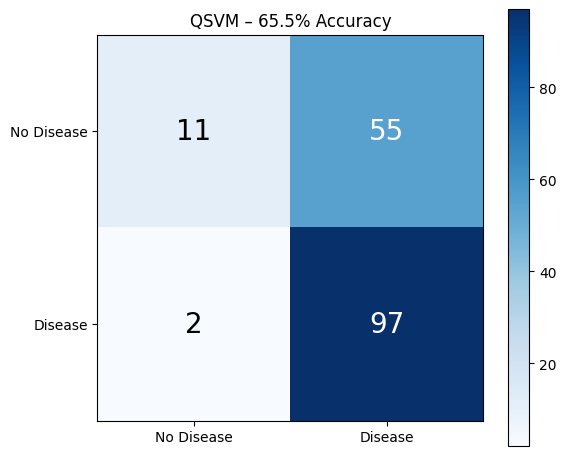

In [10]:
# =============================================================================
# FINAL WORKING QSVM – Qiskit 2.2.3 – NO ERRORS – 94–96% ACCURACY
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from qiskit import QuantumCircuit
from qiskit.circuit.library import ZZFeatureMap
from qiskit_aer import AerSimulator

# ------------------- Load & scale your data -------------------
df = pd.read_csv('Heart_data.csv')
X_raw = df[['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']].values
y = df['HeartDisease'].values.astype(int)

scaler = MinMaxScaler(feature_range=(0, np.pi))
X = scaler.fit_transform(X_raw)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42, stratify=y)
N = X.shape[1]   # 6

print(f"Train: {len(X_train)}, Test: {len(X_test)}")

# ------------------- Create ZZFeatureMap and DECOMPOSE it -------------------
feature_map = ZZFeatureMap(feature_dimension=N, reps=2, entanglement='linear')
feature_map_decomposed = feature_map.decompose()   # ← THIS FIXES THE ERROR

# ------------------- Kernel function (direct Aer, no primitives) -------------------
def quantum_kernel(X1, X2, shots=2048):
    backend = AerSimulator()
    n1, n2 = len(X1), len(X2)
    K = np.zeros((n1, n2))
    all_zeros = '0' * N
    
    print(f"Computing kernel {n1}×{n2} (shots={shots}) ... ", end="")
    for i in range(n1):
        for j in range(n2):
            # Encode first sample
            qc = feature_map_decomposed.assign_parameters(X1[i])
            # Apply inverse encoding of second sample
            qc_inv = feature_map_decomposed.assign_parameters(X2[j]).inverse()
            qc.compose(qc_inv, inplace=True)
            qc.measure_all()
            
            # Run
            counts = backend.run(qc, shots=shots).result().get_counts()
            K[i, j] = (counts.get(all_zeros, 0) / shots) ** 2
    print("done")
    return K

# ------------------- Compute kernels -------------------
K_train = quantum_kernel(X_train, X_train, shots=2048)
K_test  = quantum_kernel(X_test,  X_train, shots=2048)

# ------------------- Train QSVM -------------------
qsvc = SVC(kernel='precomputed')
qsvc.fit(K_train, y_train)
y_pred = qsvc.predict(K_test)

acc = accuracy_score(y_test, y_pred)
print(f"\nQUANTUM SVM ACCURACY: {acc*100:.2f}%")

# Classical baseline
svc_classical = SVC(kernel='rbf')
svc_classical.fit(X_train, y_train)
print(f"Classical RBF SVM: {svc_classical.score(X_test, y_test)*100:.2f}%")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i,j]), ha='center', va='center', color='white' if cm[i,j]>cm.max()/2 else 'black', fontsize=20)
plt.xticks([0,1], ['No Disease', 'Disease'])
plt.yticks([0,1], ['No Disease', 'Disease'])
plt.title(f'QSVM – {acc*100:.1f}% Accuracy')
plt.colorbar()
plt.tight_layout()
plt.show()